# Práctica: **Clasificación binaria** con Red Neuronal en PyTorch

Misma receta. En binaria: salida **1 neurona + Sigmoid**, pérdida **BCE**. El target es 0/1.


## 1. Exploración de datos
`load_breast_cancer`: 30 features numéricas, objetivo = diagnóstico (0 = benigno, 1 = maligno). Etiqueta discreta de 2 valores → **clasificación binaria**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

torch.manual_seed(0)
np.random.seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)

Dispositivo: cuda


In [2]:
data = load_breast_cancer()
X = data.data.astype(np.float32)
y = data.target.astype(np.float32)   # 0 / 1
print('X:', X.shape, '| y dist:', dict(zip(*np.unique(y, return_counts=True))))

X: (569, 30) | y dist: {np.float32(0.0): np.int64(212), np.float32(1.0): np.int64(357)}


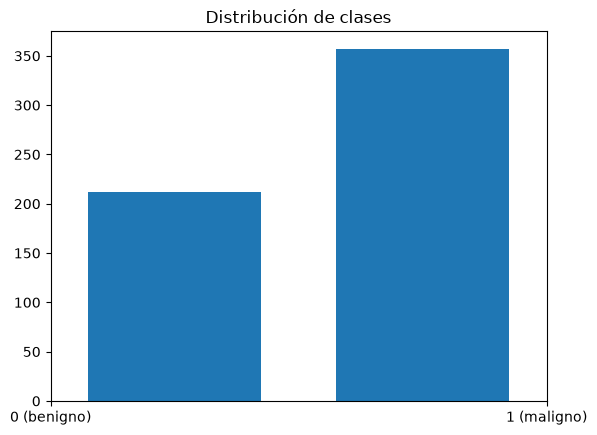

In [3]:
plt.hist(y, bins=2, rwidth=0.7)
plt.xticks([0, 1], ['0 (benigno)', '1 (maligno)'])
plt.title('Distribución de clases')
plt.show()

## 2. División y normalización
En clasificación usar `stratify=y` para que el reparto de clases quede igual en train/val/test.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.125, stratify=y_train, random_state=42)
print(f"Train: {X_train.shape[0]} | Val: {X_val.shape[0]} | Test: {X_test.shape[0]}")

Train: 398 | Val: 57 | Test: 114


In [5]:
mu = X_train.mean(axis=0)
sigma = X_train.std(axis=0)
sigma[sigma == 0] = 1
X_train = (X_train - mu) / sigma
X_val   = (X_val   - mu) / sigma
X_test  = (X_test  - mu) / sigma

## 3. Dataset y DataLoader

In [6]:
class Dataset(torch.utils.data.Dataset):
    def __init__(self, X, Y):
        self.X = torch.from_numpy(X).float().to(device)
        self.Y = torch.from_numpy(Y).float().to(device)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, ix):
        return self.X[ix], self.Y[ix]

dataset = {
    'train': Dataset(X_train, y_train),
    'val': Dataset(X_val, y_val),
}
dataloader = {
    'train': torch.utils.data.DataLoader(dataset['train'], batch_size=32, shuffle=True),
    'val': torch.utils.data.DataLoader(dataset['val'], batch_size=128, shuffle=False),
}

## 4. Modelo ⭐

Clasificación binaria → **`D_out=1` y **`Sigmoid`** al final (probabilidad de clase 1). Pérdida: **BCELoss**.

> 💡 Alternativa numéricamente más estable en PyTorch: no poner Sigmoid y usar `BCEWithLogitsLoss`. El curso usa Sigmoid+BCELoss, está bien para práctica.

In [7]:
D_in = X.shape[1]   # 30
H = 32
D_out = 1

def build_model(D_in=D_in, H=H, D_out=D_out):
    return torch.nn.Sequential(
        torch.nn.Linear(D_in, H),
        torch.nn.ReLU(),
        torch.nn.Linear(H, H),
        torch.nn.ReLU(),
        torch.nn.Linear(H, D_out),
        torch.nn.Sigmoid()   # probabilidad de clase 1
    ).to(device)

## 5. Validación de la red

In [8]:
model = build_model()
out = model(torch.randn((64, D_in)).to(device))
print('Salida:', out.shape, '| valores en (0,1)?', bool((out > 0).all() and (out < 1).all()))
assert out.shape == (64, D_out)

Salida: torch.Size([64, 1]) | valores en (0,1)? True


In [9]:
criterion = torch.nn.BCELoss()
model = build_model()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
ds1 = Dataset(X_train[:8], y_train[:8])
dl1 = torch.utils.data.DataLoader(ds1, batch_size=8)
for e in range(1, 201):
    for x_b, y_b in dl1:
        loss = criterion(model(x_b).squeeze(1), y_b)
        optimizer.zero_grad(); loss.backward(); optimizer.step()
    if not e % 50:
        print(f"Epoch {e} loss {loss.item():.5f}")

Epoch 50 loss 0.00000
Epoch 100 loss 0.00000
Epoch 150 loss 0.00000
Epoch 200 loss 0.00000


## 6. Función de entrenamiento ⭐ (con **accuracy**)

In [10]:
def fit(model, dataloader, optimizer, epochs=100, log_each=10, early_stopping=5):
    criterion = torch.nn.BCELoss()
    l, acc, val_l, val_acc = [], [], [], []
    best_acc, steps = 0, 0
    for e in range(1, epochs + 1):
        model.train()
        _l, _acc = [], []
        for x_b, y_b in dataloader['train']:
            y_pred = model(x_b).squeeze(1)
            loss = criterion(y_pred, y_b)
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            _l.append(loss.item())
            _acc.append(accuracy_score(y_b.cpu().numpy(), (y_pred > 0.5).int().cpu().numpy()))
        l.append(np.mean(_l)); acc.append(np.mean(_acc))
        model.eval()
        _vl, _vacc = [], []
        with torch.no_grad():
            for x_b, y_b in dataloader['val']:
                y_pred = model(x_b).squeeze(1)
                _vl.append(criterion(y_pred, y_b).item())
                _vacc.append(accuracy_score(y_b.cpu().numpy(), (y_pred > 0.5).int().cpu().numpy()))
        val_l.append(np.mean(_vl)); val_acc.append(np.mean(_vacc))
        if val_acc[-1] > best_acc:
            best_acc = val_acc[-1]; steps = 0
            torch.save(model.state_dict(), 'ckpt_bin.pt')
        else:
            steps += 1
        if early_stopping and steps > early_stopping:
            print(f"Early stop en epoch {e}")
            break
        if not e % log_each:
            print(f"Epoch {e}/{epochs} loss {l[-1]:.4f} acc {acc[-1]:.4f} val_acc {val_acc[-1]:.4f}")
    model.load_state_dict(torch.load('ckpt_bin.pt', weights_only=True))
    return {'loss': l, 'acc': acc, 'val_loss': val_l, 'val_acc': val_acc}

## 7. Entrenamiento y curvas

In [11]:
model = build_model()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
hist = fit(model, dataloader, optimizer, epochs=100)

Epoch 10/100 loss 0.0689 acc 0.9856 val_acc 0.9649
Early stop en epoch 16


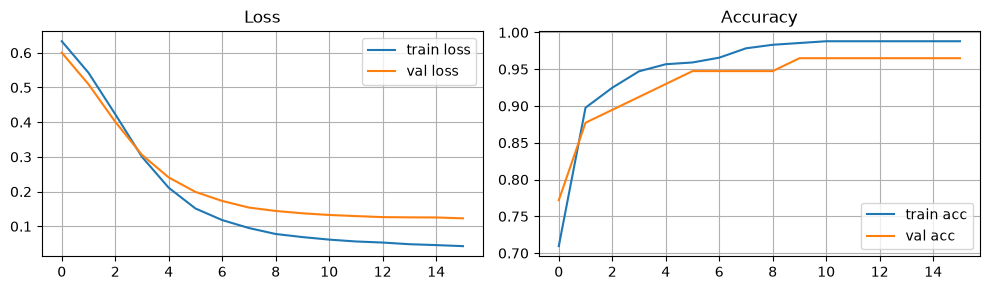

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(hist['loss'], label='train loss'); ax[0].plot(hist['val_loss'], label='val loss')
ax[0].set_title('Loss'); ax[0].legend(); ax[0].grid()
ax[1].plot(hist['acc'], label='train acc'); ax[1].plot(hist['val_acc'], label='val acc')
ax[1].set_title('Accuracy'); ax[1].legend(); ax[1].grid()
plt.tight_layout(); plt.show()

## 8. Evaluación en test
Además de accuracy se suele mirar **precision, recall, f1** y la **matriz de confusión** (útil en datos desbalanceados).

In [13]:
model.eval()
with torch.no_grad():
    y_pred = (model(torch.from_numpy(X_test).float().to(device)).squeeze(1).cpu().numpy() > 0.5).astype(int)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred, target_names=['benigno', 'maligno']))
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.9561
              precision    recall  f1-score   support

     benigno       0.95      0.93      0.94        42
     maligno       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114

[[39  3]
 [ 2 70]]


## Recapitulación
1. Target: `load_breast_cancer().target` (0/1) → **clasificación binaria**.
2. Salida: 1 neurona + **Sigmoid** → probabilidad de clase 1.
3. Pérdida: **BCE**. Predicción: `(y_pred > 0.5)`.
4. En clasificación usar `stratify=y` en el split.
5. Métricas: accuracy, precision/recall/f1, matriz de confusión.
